In [3]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
dtm = pd.read_csv("tfidf_scores.csv", index_col = 0)

In [5]:
print("Number of dimensions per text:", len(dtm.columns))

Number of dimensions per text: 14816


In [ ]:
sims = cosine_similarity(dtm)
sims = pd.DataFrame(sims, columns = dtm.index, index = dtm.index)
sims.iloc[:5, :5]

basename,ra_10923_2016,ra_10925_2017,ra_10926_2017,ra_10927_2017,ra_10928_2017
basename,,,,,
ra_10923_2016,1.000000,0.060675,0.070416,0.059216,0.060153
ra_10925_2017,0.060675,1.000000,0.644364,0.077944,0.078382
ra_10926_2017,0.070416,0.644364,1.000000,0.113330,0.086825
ra_10927_2017,0.059216,0.077944,0.113330,1.000000,0.083184
ra_10928_2017,0.060153,0.078382,0.086825,0.083184,1.000000


In [8]:
reducer = TSNE(
    n_components = 2,
    learning_rate = 'auto',
    init = 'random',
    angle = 0.35,
    random_state = 357,
    n_jobs = -1
)
reduced = reducer.fit_transform(sims)
vis = pd.DataFrame({'x': reduced[:,0], 'y': reduced[:,1], 'label': sims.index})

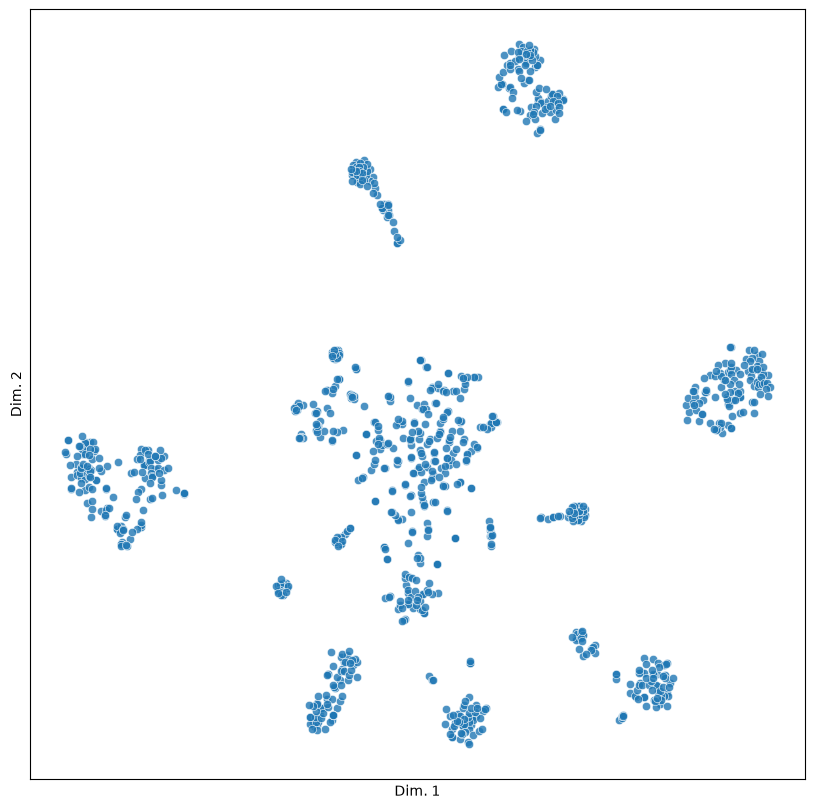

In [11]:
def sim_plot(data, hue = None, labels = None, n_colors = 3):
    """Create a scatterplot and optionally color/label its points."""
    fig, ax = plt.subplots(figsize = (10, 10))
    pal = sns.color_palette('colorblind', n_colors = n_colors) if hue else None
    g = sns.scatterplot(
        x = 'x', y = 'y', hue = hue, palette = pal, alpha = 0.8,
        data = data, ax = ax
    )
    g.set(xticks = [], yticks = [], xlabel = 'Dim. 1', ylabel = 'Dim. 2')

    if labels:
        to_label = data[data['label'].isin(labels)]
        to_label[['x', 'y', 'label']].apply(lambda x: g.text(*x), axis = 1)

    plt.show()

sim_plot(vis)

In [12]:
k = 3
agg = AgglomerativeClustering(n_clusters = k)
agg.fit(sims)

AgglomerativeClustering(n_clusters=3)

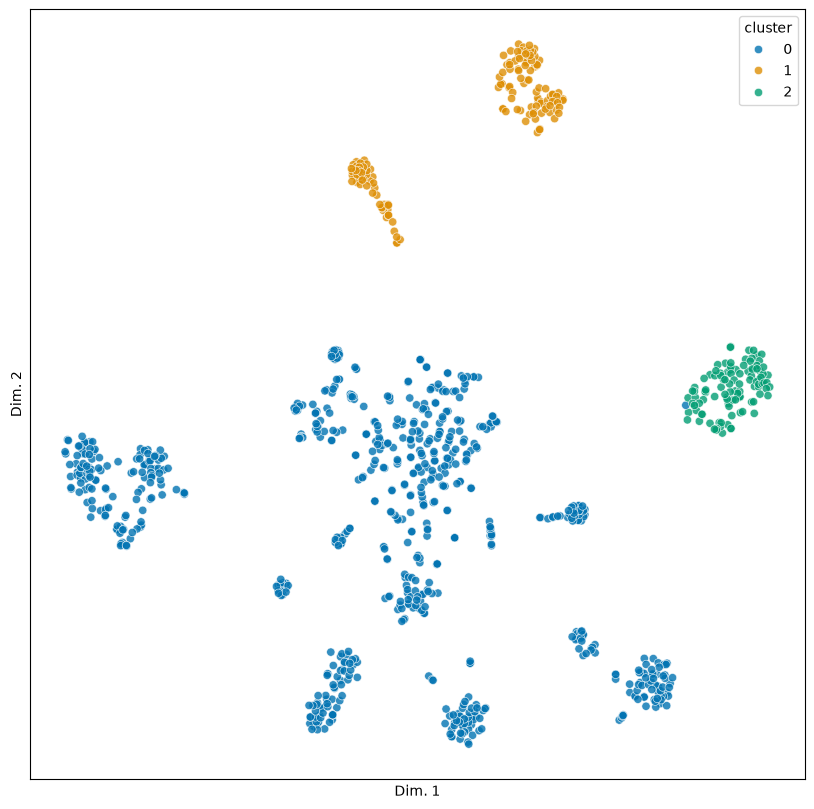

In [14]:
vis.loc[:, 'cluster'] = agg.labels_
sim_plot(vis, hue = 'cluster') 

In [15]:
n_sample = 5
for group in vis.groupby('cluster'):
    cluster, subset = group
    print(f"Cluster: {cluster}\n----------")
    samp = subset.sample(n_sample)
    for label in samp['label']:
        print(label)
    print("\n")

Cluster: 0
----------
ra_11047_2018
ra_11706_2022
ra_11727_2022
ra_11517_2020
ra_11360_2019


Cluster: 1
----------
ra_11504_2020
ra_11506_2020
ra_11415_2019
ra_11099_2018
ra_11317_2019


Cluster: 2
----------
ra_11560_2021
ra_11883_2022
ra_11716_2022
ra_11288_2019
ra_11167_2019


